# Bank Customer Churn: Neural Network Classification

Author: Mersedyes Livingston

Problem summary, data description, results and re-analysis: see [README.md](README.md).

> Built on a course-provided template. Course instructions and problem text were removed with `tools/clean_notebook.py`; code, outputs and observations are unchanged. Data is not redistributed, so cells that load it will not run as-is.


## Importing necessary libraries

In [1]:
# Installing the libraries with the specified version.
!pip install tensorflow==2.15.0 scikit-learn==1.2.2 seaborn==0.13.1 matplotlib==3.7.1 numpy==1.25.2 pandas==2.0.3 imbalanced-learn==0.10.1 -q --user

In [12]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Library to split data
from sklearn.model_selection import train_test_split

# library to import to standardize the data
from sklearn.preprocessing import StandardScaler, LabelEncoder

# importing different functions to build models
import tensorflow as tf
from tensorflow import keras
from keras import backend
from keras.models import Sequential
from keras.layers import Dense, Dropout

# importing SMOTE
from imblearn.over_sampling import SMOTE

# importing metrics
from sklearn.metrics import confusion_matrix,roc_curve,classification_report,recall_score

import random

# Library to avoid the warnings
import warnings
warnings.filterwarnings("ignore")

## Loading the dataset

In [5]:
# uncomment and run the following lines in case Colab is being used
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
ds = pd.read_csv("/content/bank-1.csv")

## Data Overview

### View the first and last 5 rows of the dataset.

In [15]:
# let's view the first 5 rows of the data
ds.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [16]:
# let's view the last 5 rows of the data
ds.tail()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


### Understand the shape of the dataset

In [17]:
# Checking the number of rows and columns in the training data
ds.shape

(10000, 14)

### Check the data types of the columns for the dataset

In [18]:
ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


### Checking the Statistical Summary

In [19]:
ds.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


### Checking for Missing Values

In [20]:
# let's check for missing values in the data
ds.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


### Checking for unique values for each of the column

In [21]:
ds.nunique()

,0
RowNumber,10000
CustomerId,10000
Surname,2932
CreditScore,460
Geography,3
Gender,2
Age,70
Tenure,11
Balance,6382
NumOfProducts,4


In [22]:
#RowNumber , CustomerId and Surname are unique hence dropping it
ds = ds.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

## Exploratory Data Analysis

### Univariate Analysis

In [23]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [24]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

#### Observations on CreditScore

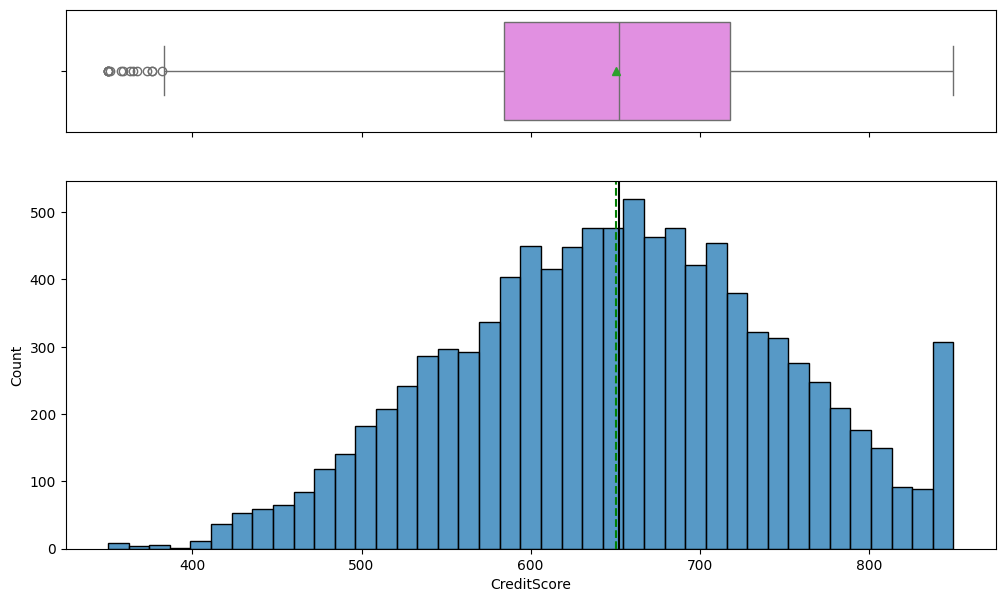

In [25]:
histogram_boxplot(ds,'CreditScore')

#### Observations on Age

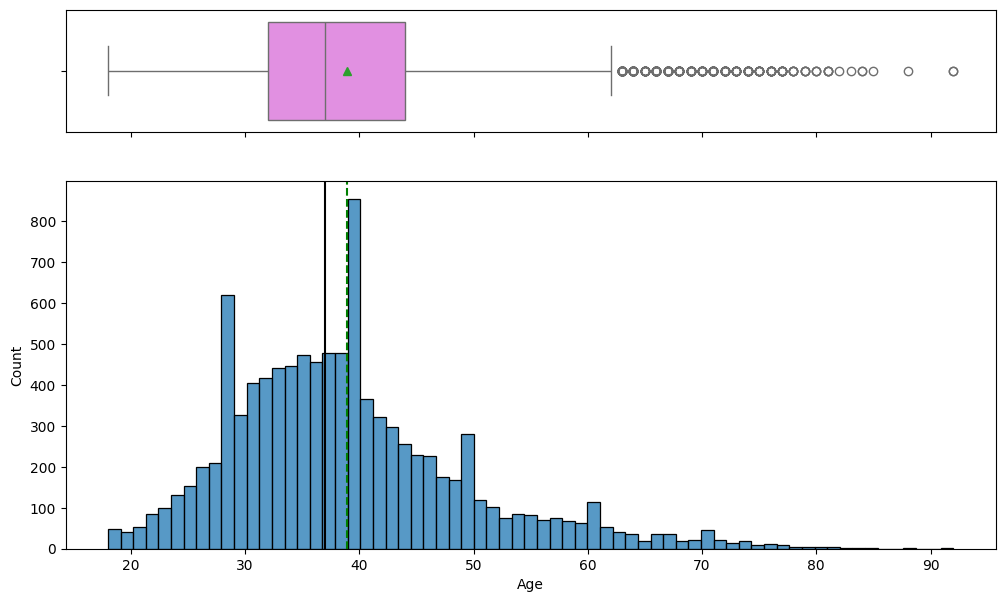

In [28]:
histogram_boxplot(ds,'Age')

#### Observations on Balance

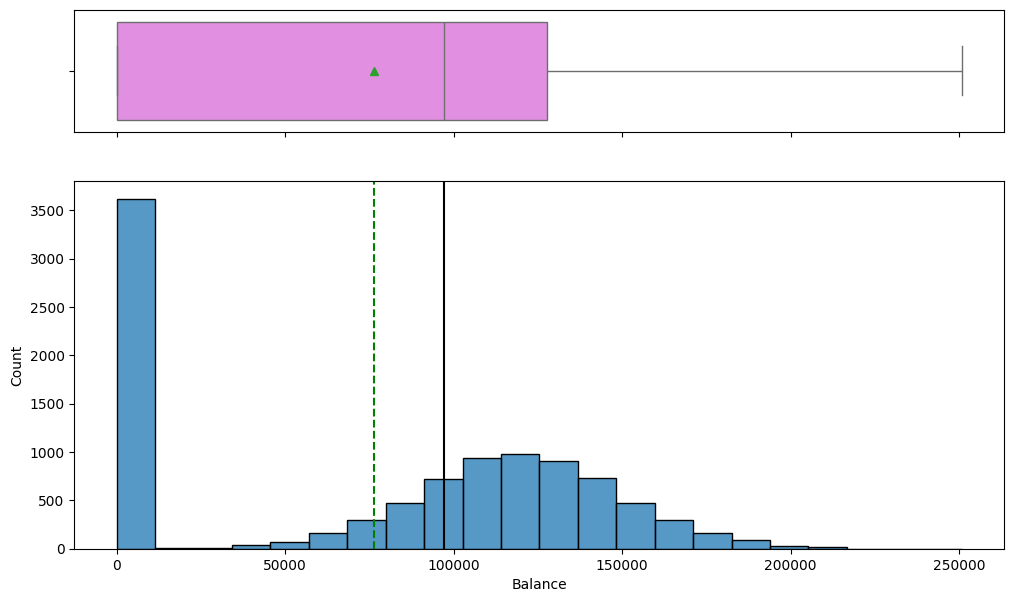

In [29]:
histogram_boxplot(ds, 'Balance')

#### Observations on Estimated Salary

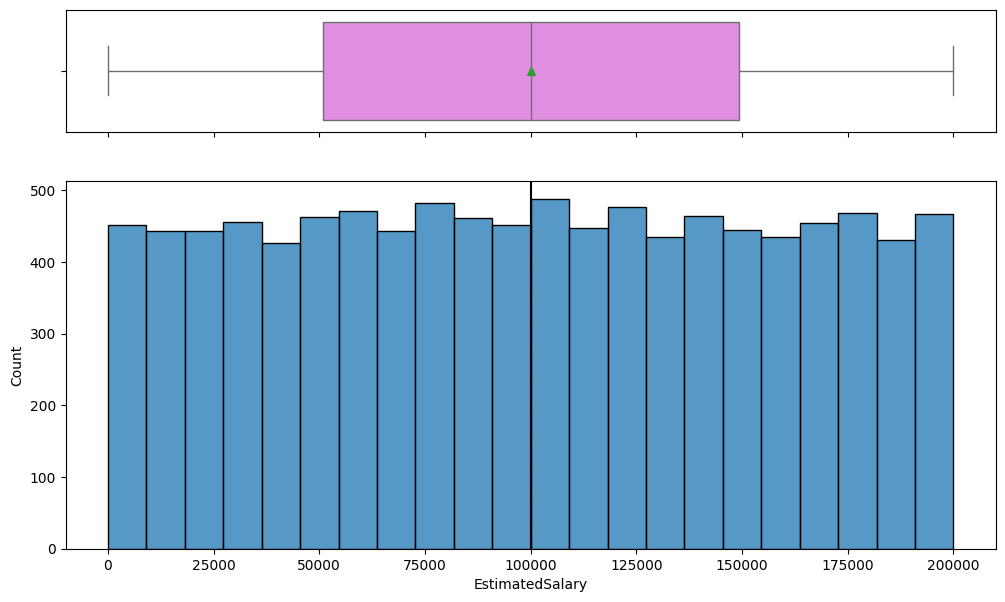

In [30]:
histogram_boxplot(ds, 'EstimatedSalary')

#### Observations on Exited

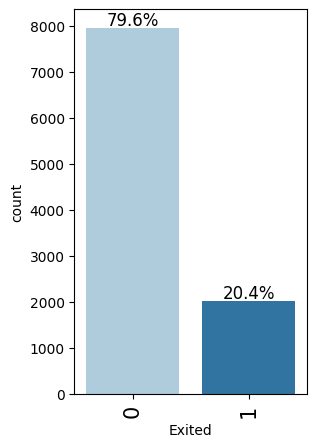

In [31]:
labeled_barplot(ds, "Exited", perc=True)

#### Observations on Geography

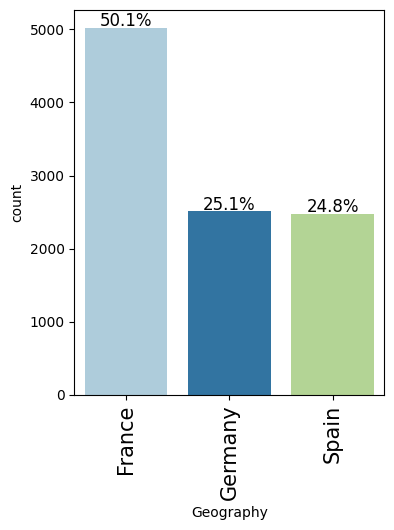

In [32]:
labeled_barplot(ds, 'Geography', perc=True)

#### Observations on Gender

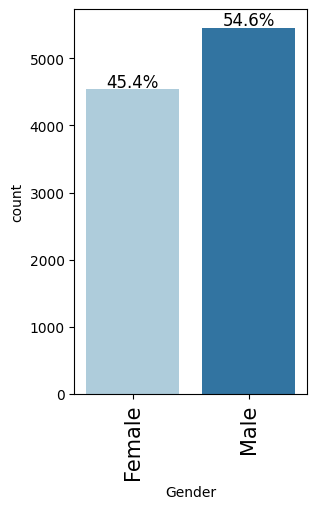

In [33]:
labeled_barplot(ds, 'Gender', perc=True)

#### Observations on Tenure

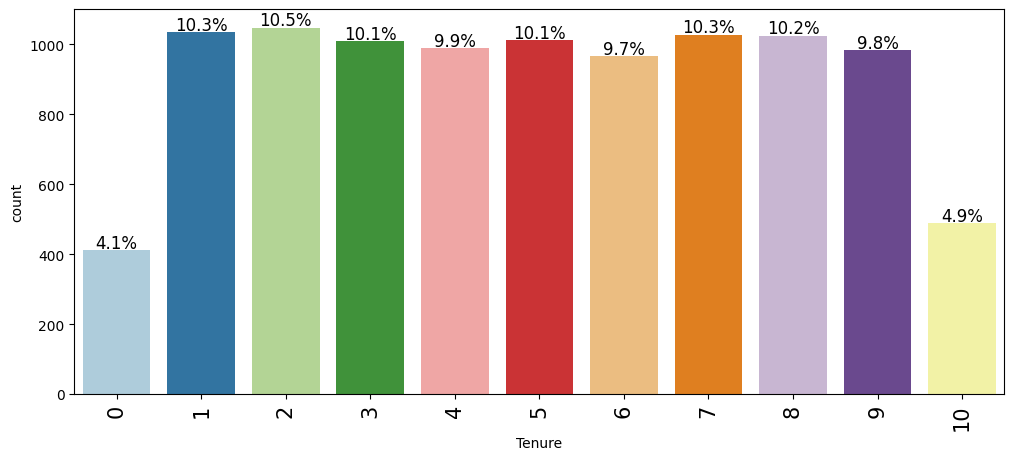

In [34]:
labeled_barplot(ds, 'Tenure', perc=True)

#### Observations on Number of Products

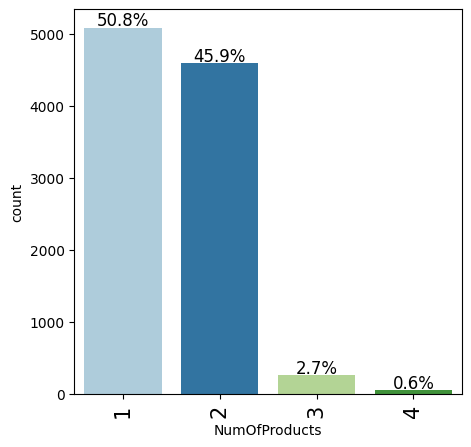

In [35]:
labeled_barplot(ds, 'NumOfProducts', perc=True)

#### Observations on Has Credit Card

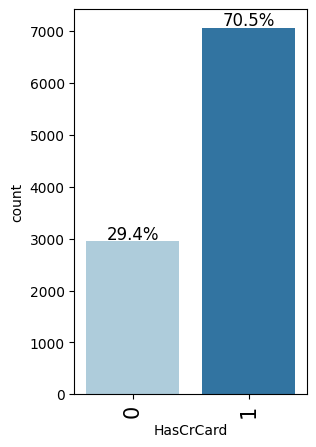

In [36]:
labeled_barplot(ds, 'HasCrCard', perc=True)

#### Observations on Is Active Member

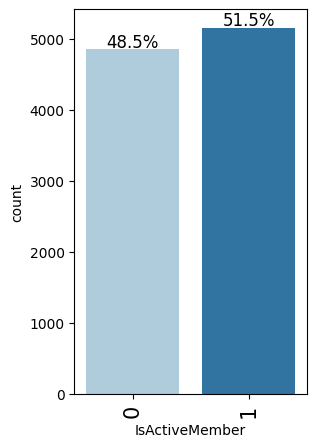

In [37]:
labeled_barplot(ds, 'IsActiveMember', perc=True)

### Bivariate Analysis

In [38]:
# function to plot stacked bar chart


def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 1, 5))
    plt.legend(
        loc="lower left",
        frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

#### Correlation plot

In [39]:
# defining the list of numerical columns
cols_list = ["CreditScore","Age","Tenure","Balance","EstimatedSalary"]

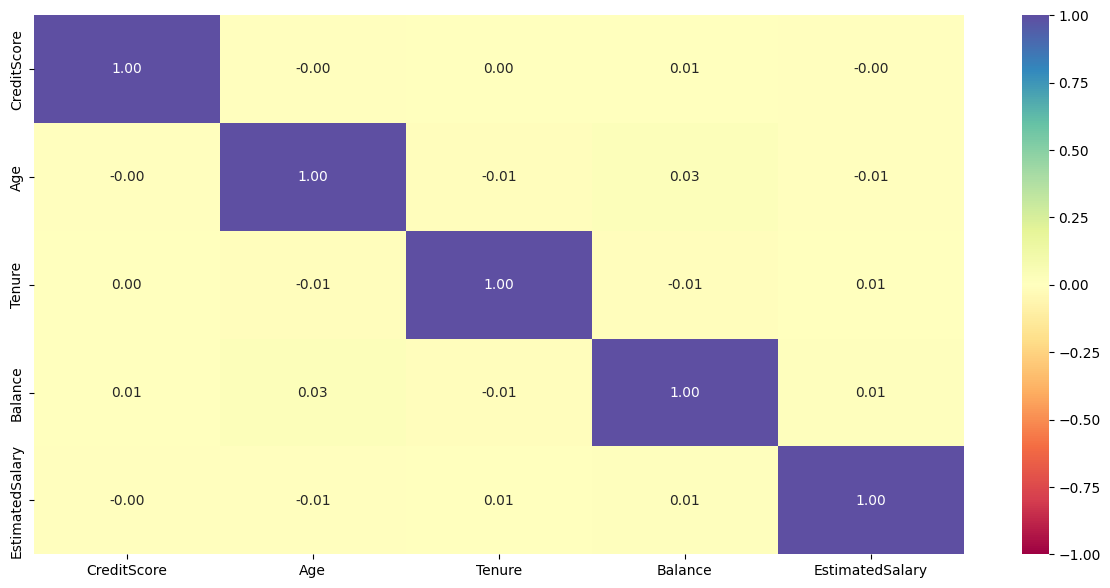

In [40]:
plt.figure(figsize=(15, 7))
sns.heatmap(ds[cols_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

#### Exited Vs Geography

Exited        0     1    All
Geography                   
All        7963  2037  10000
Germany    1695   814   2509
France     4204   810   5014
Spain      2064   413   2477
------------------------------------------------------------------------------------------------------------------------


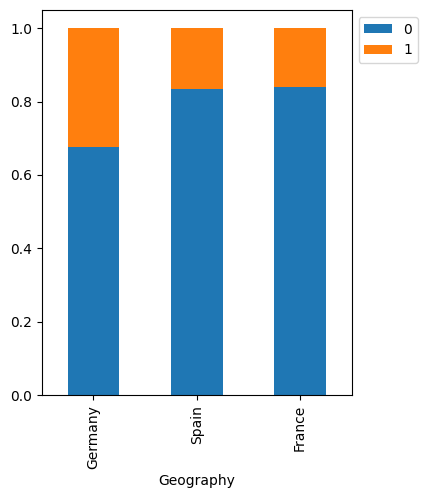

In [41]:
stacked_barplot(ds, "Geography", "Exited" )

#### Exited Vs Gender

Exited     0     1    All
Gender                   
All     7963  2037  10000
Female  3404  1139   4543
Male    4559   898   5457
------------------------------------------------------------------------------------------------------------------------


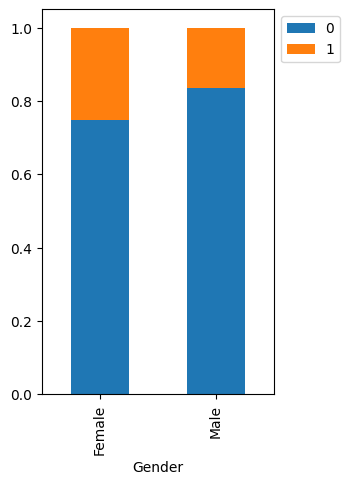

In [42]:
stacked_barplot(ds, 'Gender', 'Exited')

#### Exited Vs Has Credit Card

Exited        0     1    All
HasCrCard                   
All        7963  2037  10000
1          5631  1424   7055
0          2332   613   2945
------------------------------------------------------------------------------------------------------------------------


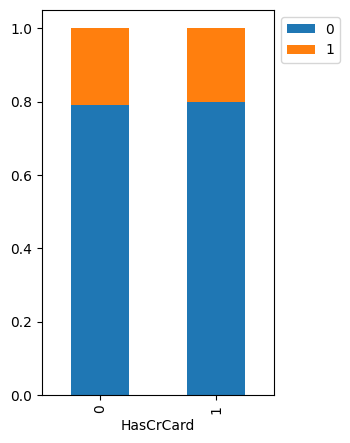

In [43]:
stacked_barplot(ds, 'HasCrCard', 'Exited')

#### Exited Vs Is active member

Exited             0     1    All
IsActiveMember                   
All             7963  2037  10000
0               3547  1302   4849
1               4416   735   5151
------------------------------------------------------------------------------------------------------------------------


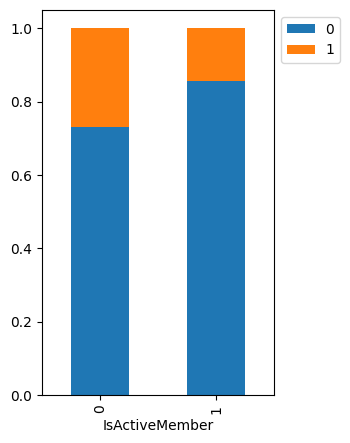

In [44]:
stacked_barplot(ds, 'IsActiveMember', 'Exited')

#### Exited Vs Credit Score

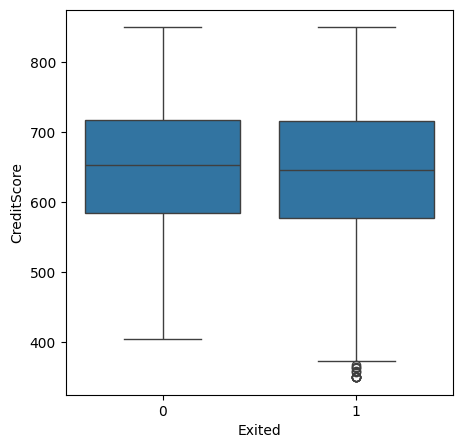

In [45]:
plt.figure(figsize=(5,5))
sns.boxplot(y='CreditScore',x='Exited',data=ds)
plt.show()

#### Exited Vs Age

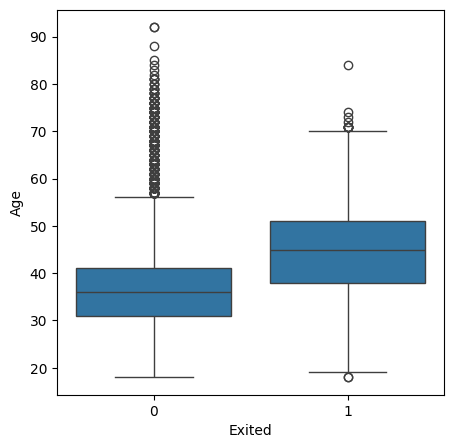

In [46]:
plt.figure(figsize=(5,5))
sns.boxplot(y='Age',x='Exited',data=ds)
plt.show()

#### Exited Vs Tenure

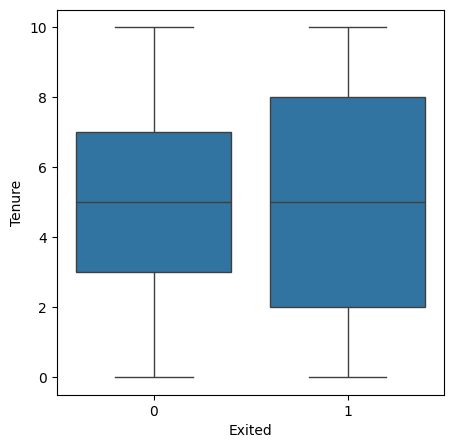

In [47]:
plt.figure(figsize=(5,5))
sns.boxplot(y='Tenure',x='Exited',data=ds)
plt.show()

#### Exited Vs Balance

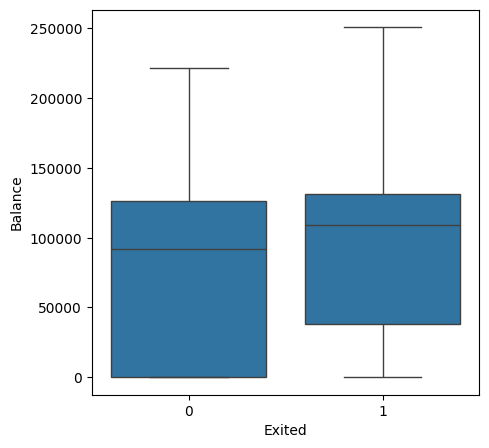

In [48]:
plt.figure(figsize=(5,5))
sns.boxplot(y='Balance',x='Exited',data=ds)
plt.show()

#### Exited Vs Number of Products

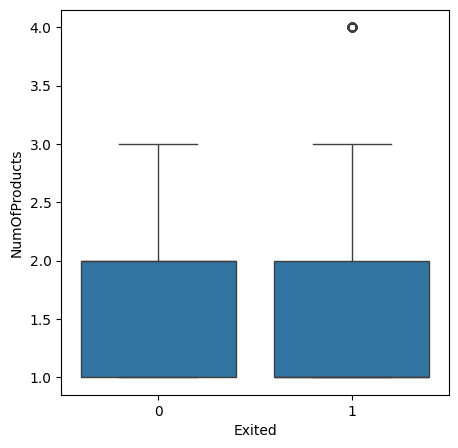

In [49]:
plt.figure(figsize=(5,5))
sns.boxplot(y='NumOfProducts',x='Exited',data=ds)
plt.show()

#### Exited Vs Estimated Salary

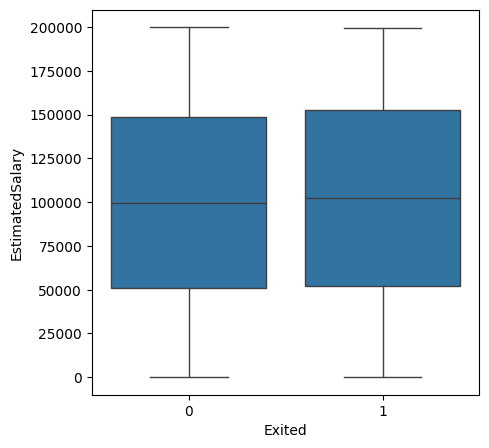

In [50]:
plt.figure(figsize=(5,5))
sns.boxplot(y='EstimatedSalary',x='Exited',data=ds)
plt.show()

## Data Preprocessing

### Dummy Variable Creation

In [51]:
ds = pd.get_dummies(ds,columns=ds.select_dtypes(include=["object"]).columns.tolist(),drop_first=True)
ds = ds.astype(float)
ds.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619.0,42.0,2.0,0.00,1.0,1.0,1.0,101348.88,1.0,0.0,0.0,0.0
1,608.0,41.0,1.0,83807.86,1.0,0.0,1.0,112542.58,0.0,0.0,1.0,0.0
2,502.0,42.0,8.0,159660.80,3.0,1.0,0.0,113931.57,1.0,0.0,0.0,0.0
3,699.0,39.0,1.0,0.00,2.0,0.0,0.0,93826.63,0.0,0.0,0.0,0.0
4,850.0,43.0,2.0,125510.82,1.0,1.0,1.0,79084.10,0.0,0.0,1.0,0.0


### Train-validation-test Split

In [52]:
X = ds.drop(['Exited'],axis=1) # Credit Score through Estimated Salary
y = ds['Exited'] # Exited

In [53]:
# Splitting the dataset into the Training and Testing set.

X_large, X_test, y_large, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42,stratify=y,shuffle = True)

In [54]:
# Splitting the dataset into the Training and Testing set.

X_train, X_val, y_train, y_val = train_test_split(X_large, y_large, test_size = 0.25, random_state = 42,stratify=y_large, shuffle = True)

In [55]:
print(X_train.shape, X_val.shape, X_test.shape)

(6000, 11) (2000, 11) (2000, 11)


In [56]:
print(y_train.shape, y_val.shape, y_test.shape)

(6000,) (2000,) (2000,)


### Data Normalization

Since all the numerical values are on a different scale, so we will be scaling all the numerical values to bring them to the same scale.

In [57]:
# creating an instance of the standard scaler
sc = StandardScaler()

X_train[cols_list] = sc.fit_transform(X_train[cols_list])
X_val[cols_list] = sc.transform(X_val[cols_list])
X_test[cols_list] = sc.transform(X_test[cols_list])

## Model Building

### Model Evaluation Criterion

Write down the logic for choosing the metric that would be the best metric for this business scenario.

-


**Let's create a function for plotting the confusion matrix**



In [58]:
def make_confusion_matrix(actual_targets, predicted_targets):
    """
    To plot the confusion_matrix with percentages

    actual_targets: actual target (dependent) variable values
    predicted_targets: predicted target (dependent) variable values
    """
    cm = confusion_matrix(actual_targets, predicted_targets)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(cm.shape[0], cm.shape[1])

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

Let's create two blank dataframes that will store the recall values for all the models we build.

In [59]:
train_metric_df = pd.DataFrame(columns=["recall"])
valid_metric_df = pd.DataFrame(columns=["recall"])

### Neural Network with SGD Optimizer

In [60]:
backend.clear_session()
#Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [62]:
#Initializing the neural network
model_0 = Sequential()
# Adding the input layer with 64 neurons and relu as activation function
model_0.add(Dense(64, activation='relu', input_dim = X_train.shape[1]))
model_0.add(Dense(32, activation='relu')) # Added a hidden layer with 32 neurons and relu activation
model_0.add(Dense(1, activation = 'sigmoid')) # Added the output layer with 1 neuron for binary classification and sigmoid activation

In [63]:
optimizer = tf.keras.optimizers.SGD(0.001)

# uncomment one of the following lines to define the metric to be used
# metric = 'accuracy'
metric = keras.metrics.Recall()
# metric = keras.metrics.Precision()
# metric = keras.metrics.F1Score()

In [64]:
model_0.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [65]:
model_0.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_1 (Dense)             (None, 64)                768       
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dense_3 (Dense)             (None, 1)                 33        
                                                                 
Total params: 2881 (11.25 KB)
Trainable params: 2881 (11.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [66]:
# Fitting the ANN

history_0 = model_0.fit(
    X_train, y_train,
    batch_size=32,
    validation_data=(X_val,y_val),
    epochs=50,
    verbose=1
)

Epoch 1/50
188/188 [==============================] - 1s 3ms/step - loss: 0.6360 - recall: 0.0630 - val_loss: 0.6000 - val_recall: 0.0123
Epoch 2/50
188/188 [==============================] - 0s 2ms/step - loss: 0.5792 - recall: 0.0057 - val_loss: 0.5556 - val_recall: 0.0025
Epoch 3/50
188/188 [==============================] - 0s 2ms/step - loss: 0.5439 - recall: 8.1766e-04 - val_loss: 0.5277 - val_recall: 0.0000e+00
Epoch 4/50
188/188 [==============================] - 0s 2ms/step - loss: 0.5219 - recall: 0.0000e+00 - val_loss: 0.5101 - val_recall: 0.0000e+00
Epoch 5/50
188/188 [==============================] - 0s 2ms/step - loss: 0.5079 - recall: 0.0000e+00 - val_loss: 0.4988 - val_recall: 0.0000e+00
Epoch 6/50
188/188 [==============================] - 0s 2ms/step - loss: 0.4988 - recall: 0.0000e+00 - val_loss: 0.4913 - val_recall: 0.0000e+00
Epoch 7/50
188/188 [==============================] - 0s 2ms/step - loss: 0.4926 - recall: 0.0000e+00 - val_loss: 0.4860 - val_recall: 0.000

**Loss function**

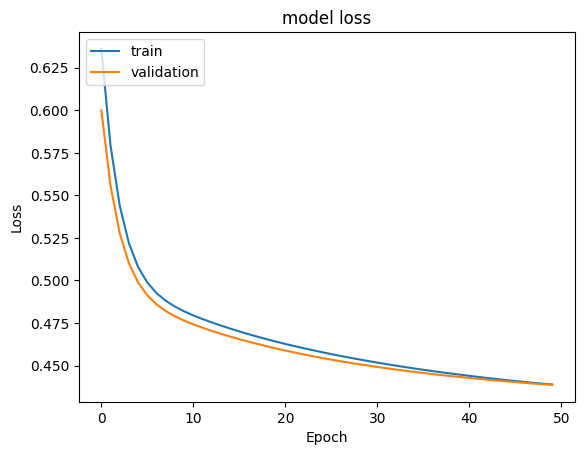

In [67]:
#Plotting Train Loss vs Validation Loss
plt.plot(history_0.history['loss'])
plt.plot(history_0.history['val_loss'])
plt.title('model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

**Recall**

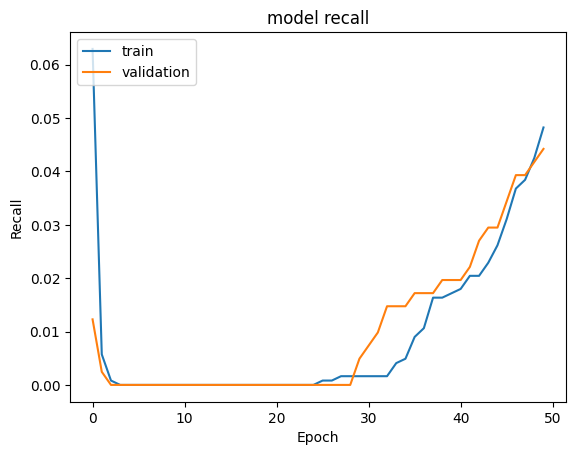

In [68]:
#Plotting Train recall vs Validation recall
plt.plot(history_0.history['recall'])
plt.plot(history_0.history['val_recall'])
plt.title('model recall')
plt.ylabel('Recall')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [69]:
#Predicting the results using best as a threshold
y_train_pred = model_0.predict(X_train)
y_train_pred = (y_train_pred > 0.5)
y_train_pred

188/188 [==============================] - 0s 886us/step


array([[False],
       [False],
       [False],
       ...,
       [False],
       [False],
       [False]])

In [71]:
#Predicting the results using best as a threshold
y_val_pred = model_0.predict(X_val)
y_val_pred = (y_val_pred > 0.5)
y_val_pred

63/63 [==============================] - 0s 1ms/step


array([[False],
       [False],
       [False],
       ...,
       [False],
       [False],
       [False]])

In [72]:
model_name = "NN with SGD"

train_metric_df.loc[model_name] = recall_score(y_train, y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val, y_val_pred)

**Classification report**

In [73]:
#lassification report
cr = classification_report(y_train, y_train_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.80      0.99      0.89      4777
         1.0       0.57      0.05      0.09      1223

    accuracy                           0.80      6000
   macro avg       0.69      0.52      0.49      6000
weighted avg       0.76      0.80      0.72      6000



In [74]:
#classification report
cr=classification_report(y_val, y_val_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.80      0.99      0.89      1593
         1.0       0.58      0.04      0.08       407

    accuracy                           0.80      2000
   macro avg       0.69      0.52      0.48      2000
weighted avg       0.76      0.80      0.72      2000



**Confusion matrix**

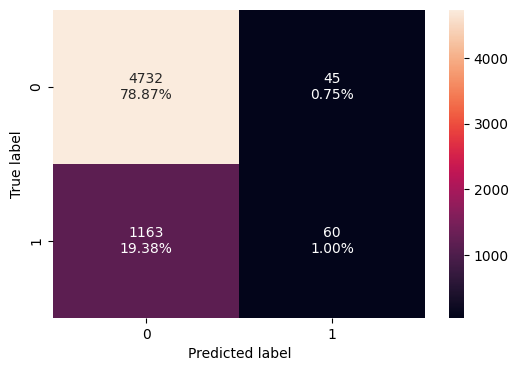

In [75]:
make_confusion_matrix(y_train, y_train_pred)

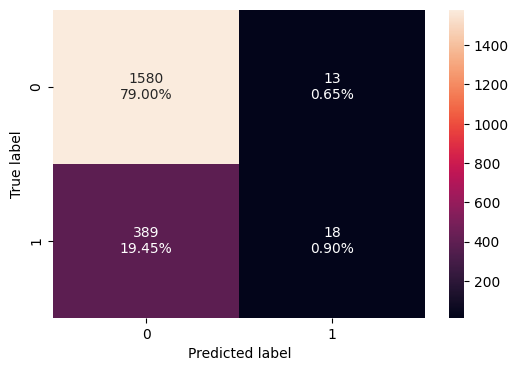

In [76]:
make_confusion_matrix(y_val, y_val_pred)

## Model Performance Improvement

### Neural Network with Adam Optimizer

In [77]:
backend.clear_session()
#Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [78]:
#Initializing the neural network
model_1 = Sequential()
model_1.add(Dense(64,activation='relu',input_dim = X_train.shape[1]))
model_1.add(Dense(32,activation='relu'))
model_1.add(Dense(1, activation = 'sigmoid'))

In [79]:
optimizer = tf.keras.optimizers.Adam()

# uncomment one of the following lines to define the metric to be used
# metric = 'accuracy'
# metric = keras.metrics.Recall()
# metric = keras.metrics.Precision()
# metric = keras.metrics.F1Score()

In [80]:
model_1.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [81]:
model_1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                768       
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 1)                 33        
                                                                 
Total params: 2881 (11.25 KB)
Trainable params: 2881 (11.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [82]:
#Fitting the ANN
history_1 = model_1.fit(
    X_train,y_train,
    batch_size=32,
    validation_data=(X_val,y_val),
    epochs=50,
    verbose=1
)

Epoch 1/50
188/188 [==============================] - 1s 3ms/step - loss: 0.4575 - recall: 0.0847 - val_loss: 0.4252 - val_recall: 0.2088
Epoch 2/50
188/188 [==============================] - 0s 2ms/step - loss: 0.4122 - recall: 0.2608 - val_loss: 0.4150 - val_recall: 0.2948
Epoch 3/50
188/188 [==============================] - 0s 2ms/step - loss: 0.3981 - recall: 0.3189 - val_loss: 0.4081 - val_recall: 0.3538
Epoch 4/50
188/188 [==============================] - 0s 2ms/step - loss: 0.3866 - recall: 0.3475 - val_loss: 0.4016 - val_recall: 0.3735
Epoch 5/50
188/188 [==============================] - 0s 2ms/step - loss: 0.3768 - recall: 0.3810 - val_loss: 0.3934 - val_recall: 0.3391
Epoch 6/50
188/188 [==============================] - 0s 2ms/step - loss: 0.3701 - recall: 0.3982 - val_loss: 0.3867 - val_recall: 0.3661
Epoch 7/50
188/188 [==============================] - 0s 2ms/step - loss: 0.3613 - recall: 0.4088 - val_loss: 0.3822 - val_recall: 0.3636
Epoch 8/50
188/188 [==============

**Loss function**

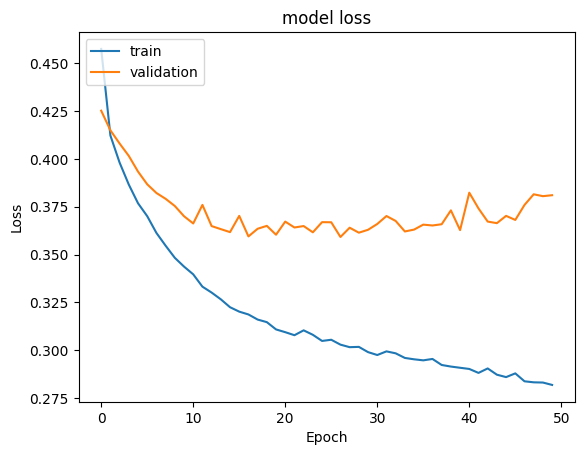

In [83]:
#Plotting Train Loss vs Validation Loss
plt.plot(history_1.history['loss'])
plt.plot(history_1.history['val_loss'])
plt.title('model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

**Recall**

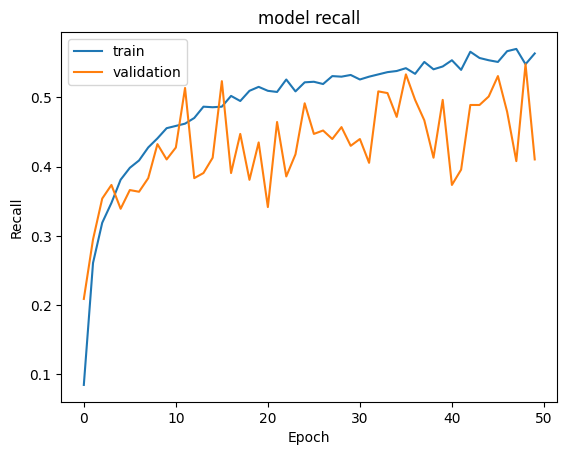

In [84]:
#Plotting Train recall vs Validation recall
plt.plot(history_1.history['recall'])
plt.plot(history_1.history['val_recall'])
plt.title('model recall')
plt.ylabel('Recall')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [85]:
#Predicting the results using 0.5 as the threshold
y_train_pred = model_1.predict(X_train)
y_train_pred = (y_train_pred > 0.5)
y_train_pred

188/188 [==============================] - 0s 911us/step


array([[False],
       [False],
       [False],
       ...,
       [ True],
       [False],
       [ True]])

In [86]:
#Predicting the results using 0.5 as the threshold
y_val_pred = model_1.predict(X_val)
y_val_pred = (y_val_pred > 0.5)
y_val_pred

63/63 [==============================] - 0s 869us/step


array([[False],
       [False],
       [ True],
       ...,
       [False],
       [False],
       [False]])

In [87]:
model_name = "NN with Adam"

train_metric_df.loc[model_name] = recall_score(y_train,y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val,y_val_pred)

**Classification report**

In [88]:
#lassification report
cr=classification_report(y_train,y_train_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.89      0.98      0.93      4777
         1.0       0.85      0.51      0.64      1223

    accuracy                           0.88      6000
   macro avg       0.87      0.75      0.79      6000
weighted avg       0.88      0.88      0.87      6000



In [89]:
#classification report
cr=classification_report(y_val,y_val_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.87      0.97      0.91      1593
         1.0       0.75      0.41      0.53       407

    accuracy                           0.85      2000
   macro avg       0.81      0.69      0.72      2000
weighted avg       0.84      0.85      0.83      2000



**Confusion matrix**

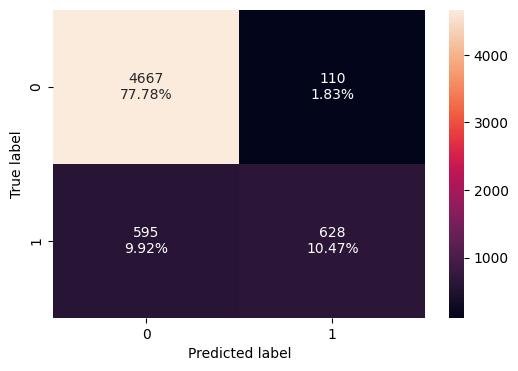

In [90]:
#Calculating the confusion matrix
make_confusion_matrix(y_train, y_train_pred)

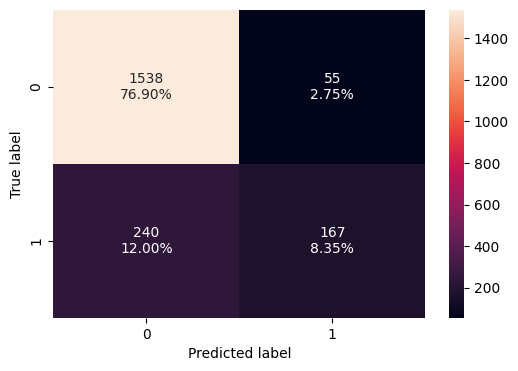

In [91]:
#Calculating the confusion matrix
make_confusion_matrix(y_val,y_val_pred)

### Neural Network with Adam Optimizer and Dropout

In [92]:
backend.clear_session()
#Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [93]:
#Initializing the neural network
model_2 = Sequential()
#Adding the input layer with 32 neurons and relu as activation function
model_2.add(Dense(32,activation='relu',input_dim = X_train.shape[1]))
model_2.add(Dropout(0.2))
model_2.add(Dense(16,activation='relu'))
model_2.add(Dense(8,activation='relu'))
model_2.add(Dropout(0.1))
model_2.add(Dense(4,activation='relu'))
model_2.add(Dense(1, activation = 'sigmoid'))

In [94]:
optimizer = tf.keras.optimizers.Adam()

# uncomment one of the following lines to define the metric to be used
# metric = 'accuracy'
# metric = keras.metrics.Recall()
# metric = keras.metrics.Precision()
# metric = keras.metrics.F1Score()

In [95]:
model_2.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [96]:
# Summary of the model
model_2.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 32)                384       
                                                                 
 dropout (Dropout)           (None, 32)                0         
                                                                 
 dense_1 (Dense)             (None, 16)                528       
                                                                 
 dense_2 (Dense)             (None, 8)                 136       
                                                                 
 dropout_1 (Dropout)         (None, 8)                 0         
                                                                 
 dense_3 (Dense)             (None, 4)                 36        
                                                                 
 dense_4 (Dense)             (None, 1)                 5

In [97]:
#Fitting the ANN with batch_size = 32 and 100 epochs
history_2 = model_2.fit(
    X_train,y_train,
    batch_size=32,
    epochs=100,
    verbose=1,
    validation_data=(X_val,y_val)
)

Epoch 1/100
188/188 [==============================] - 1s 3ms/step - loss: 0.4873 - recall: 0.1025 - val_loss: 0.4511 - val_recall: 0.0000e+00
Epoch 2/100
188/188 [==============================] - 0s 2ms/step - loss: 0.4534 - recall: 0.0074 - val_loss: 0.4355 - val_recall: 0.0000e+00
Epoch 3/100
188/188 [==============================] - 0s 2ms/step - loss: 0.4385 - recall: 0.0237 - val_loss: 0.4298 - val_recall: 0.0147
Epoch 4/100
188/188 [==============================] - 0s 2ms/step - loss: 0.4382 - recall: 0.0875 - val_loss: 0.4256 - val_recall: 0.0835
Epoch 5/100
188/188 [==============================] - 0s 2ms/step - loss: 0.4307 - recall: 0.1464 - val_loss: 0.4209 - val_recall: 0.2162
Epoch 6/100
188/188 [==============================] - 0s 2ms/step - loss: 0.4252 - recall: 0.2077 - val_loss: 0.4151 - val_recall: 0.2506
Epoch 7/100
188/188 [==============================] - 0s 2ms/step - loss: 0.4184 - recall: 0.2625 - val_loss: 0.4108 - val_recall: 0.2432
Epoch 8/100
188/188

**Loss function**

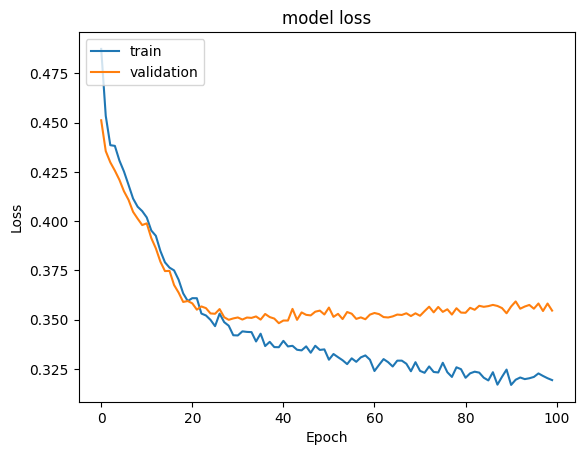

In [98]:
#Plotting Train Loss vs Validation Loss
plt.plot(history_2.history['loss'])
plt.plot(history_2.history['val_loss'])
plt.title('model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

From the above plot, we can observe that the train and validation curves are having smooth lines. Reducing the number of neurons and adding dropouts to the model worked, and the problem of overfitting was solved.

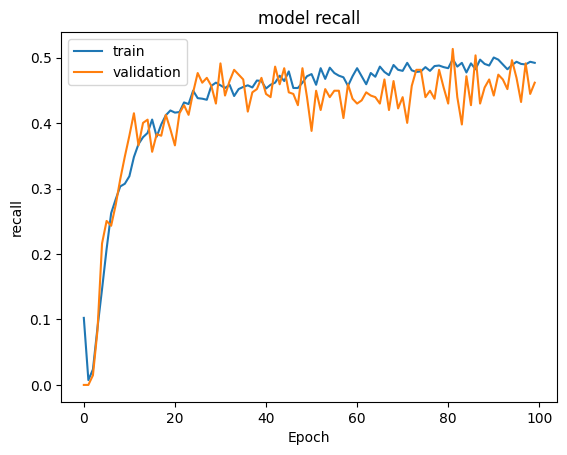

In [99]:
#Plotting Train recall vs Validation recall
plt.plot(history_2.history['recall'])
plt.plot(history_2.history['val_recall'])
plt.title('model recall')
plt.ylabel('recall')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [100]:
#Predicting the results using best as a threshold
y_train_pred = model_2.predict(X_train)
y_train_pred = (y_train_pred > 0.5)
y_train_pred

188/188 [==============================] - 0s 1ms/step


array([[False],
       [False],
       [ True],
       ...,
       [ True],
       [False],
       [ True]])

In [101]:
#Predicting the results using 0.5 as the threshold.
y_val_pred = model_2.predict(X_val)
y_val_pred = (y_val_pred > 0.5)
y_val_pred

63/63 [==============================] - 0s 929us/step


array([[False],
       [False],
       [False],
       ...,
       [False],
       [False],
       [False]])

In [102]:
model_name = "NN with Adam & Dropout"

train_metric_df.loc[model_name] = recall_score(y_train,y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val,y_val_pred)

**Classification report**

In [103]:
#classification report
cr=classification_report(y_train,y_train_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.89      0.97      0.93      4777
         1.0       0.83      0.54      0.65      1223

    accuracy                           0.88      6000
   macro avg       0.86      0.75      0.79      6000
weighted avg       0.88      0.88      0.87      6000



In [104]:
#classification report
cr = classification_report(y_val,y_val_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.87      0.96      0.91      1593
         1.0       0.73      0.46      0.57       407

    accuracy                           0.86      2000
   macro avg       0.80      0.71      0.74      2000
weighted avg       0.85      0.86      0.84      2000



**Confusion matrix**

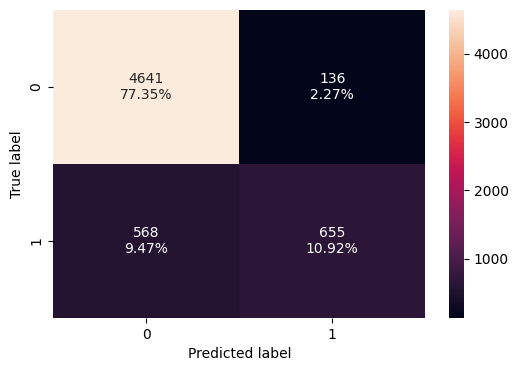

In [105]:
#Calculating the confusion matrix
make_confusion_matrix(y_train, y_train_pred)

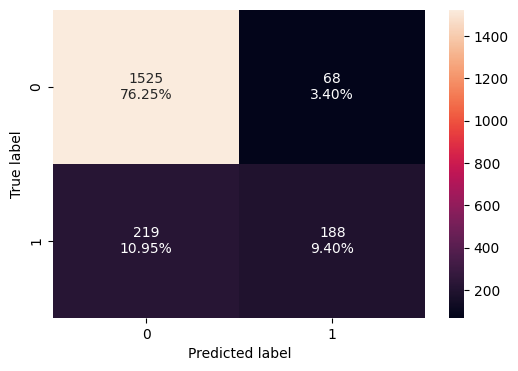

In [106]:
#Calculating the confusion matrix
make_confusion_matrix(y_val,y_val_pred)

### Neural Network with Balanced Data (by applying SMOTE) and SGD Optimizer

**Let's try to apply SMOTE to balance this dataset and then again apply hyperparamter tuning accordingly.**

In [107]:
sm  = SMOTE(random_state=42)
X_train_smote, y_train_smote= sm.fit_resample(X_train, y_train)
print('After UpSampling, the shape of train_X: {}'.format(X_train_smote.shape))
print('After UpSampling, the shape of train_y: {} \n'.format(y_train_smote.shape))

After UpSampling, the shape of train_X: (9554, 11)
After UpSampling, the shape of train_y: (9554,) 



Let's build a model with the balanced dataset

In [108]:
backend.clear_session()
#Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [109]:
#Initializing the model
model_3 = Sequential()
model_3.add(Dense(64,activation='relu',input_dim = X_train_smote.shape[1]))
model_3.add(Dense(16,activation='relu'))
model_3.add(Dense(8,activation='relu'))
model_3.add(Dense(1, activation = 'sigmoid'))

In [110]:
optimizer = tf.keras.optimizers.SGD(0.001)

# uncomment one of the following lines to define the metric to be used
# metric = 'accuracy'
metric = keras.metrics.Recall()
# metric = keras.metrics.Precision()
# metric = keras.metrics.F1Score()

In [111]:
model_3.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [112]:
model_3.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                768       
                                                                 
 dense_1 (Dense)             (None, 16)                1040      
                                                                 
 dense_2 (Dense)             (None, 8)                 136       
                                                                 
 dense_3 (Dense)             (None, 1)                 9         
                                                                 
Total params: 1953 (7.63 KB)
Trainable params: 1953 (7.63 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [113]:
#Fitting the ANN
history_3 = model_3.fit(
    X_train_smote, y_train_smote,
    batch_size=32,
    epochs=50,
    verbose=1,
    validation_data = (X_val,y_val)
)

Epoch 1/50
299/299 [==============================] - 1s 2ms/step - loss: 0.6902 - recall: 0.9401 - val_loss: 0.7154 - val_recall: 0.9140
Epoch 2/50
299/299 [==============================] - 1s 2ms/step - loss: 0.6870 - recall: 0.8851 - val_loss: 0.7050 - val_recall: 0.8575
Epoch 3/50
299/299 [==============================] - 0s 2ms/step - loss: 0.6841 - recall: 0.8078 - val_loss: 0.6960 - val_recall: 0.7813
Epoch 4/50
299/299 [==============================] - 0s 2ms/step - loss: 0.6813 - recall: 0.7544 - val_loss: 0.6878 - val_recall: 0.7420
Epoch 5/50
299/299 [==============================] - 0s 2ms/step - loss: 0.6784 - recall: 0.7065 - val_loss: 0.6801 - val_recall: 0.6609
Epoch 6/50
299/299 [==============================] - 0s 2ms/step - loss: 0.6754 - recall: 0.6598 - val_loss: 0.6729 - val_recall: 0.6290
Epoch 7/50
299/299 [==============================] - 0s 2ms/step - loss: 0.6722 - recall: 0.6299 - val_loss: 0.6659 - val_recall: 0.6143
Epoch 8/50
299/299 [==============

**Loss function**

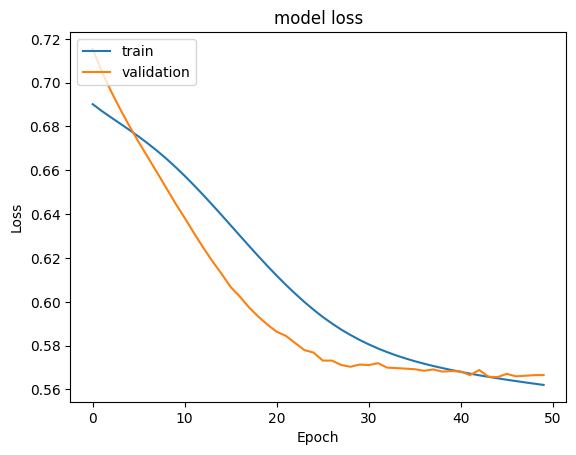

In [114]:
#Plotting Train Loss vs Validation Loss
plt.plot(history_3.history['loss'])
plt.plot(history_3.history['val_loss'])
plt.title('model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

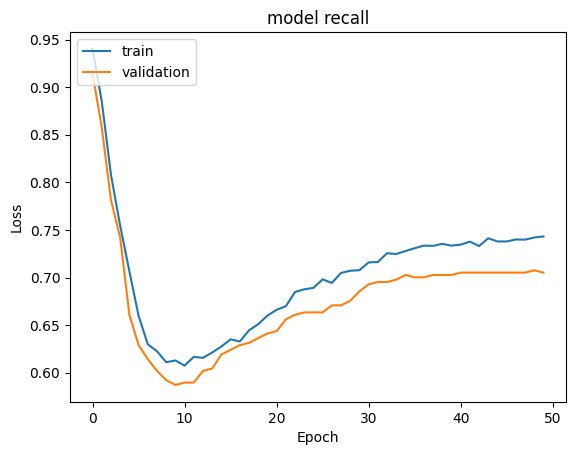

In [115]:
#Plotting Train recall vs Validation recall
plt.plot(history_3.history['recall'])
plt.plot(history_3.history['val_recall'])
plt.title('model recall')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [116]:
y_train_pred = model_3.predict(X_train_smote)
#Predicting the results using 0.5 as the threshold
y_train_pred = (y_train_pred > 0.5)
y_train_pred

299/299 [==============================] - 0s 906us/step


array([[ True],
       [ True],
       [False],
       ...,
       [ True],
       [False],
       [ True]])

In [117]:
y_val_pred = model_3.predict(X_val)
#Predicting the results using 0.5 as the threshold
y_val_pred = (y_val_pred > 0.5)
y_val_pred

63/63 [==============================] - 0s 917us/step


array([[False],
       [False],
       [ True],
       ...,
       [False],
       [False],
       [ True]])

In [118]:
model_name = "NN with SMOTE & SGD"

train_metric_df.loc[model_name] = recall_score(y_train_smote,y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val,y_val_pred)

**Classification report**

In [119]:
cr=classification_report(y_train_smote,y_train_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.74      0.71      0.72      4777
         1.0       0.72      0.75      0.73      4777

    accuracy                           0.73      9554
   macro avg       0.73      0.73      0.73      9554
weighted avg       0.73      0.73      0.73      9554



In [120]:
cr=classification_report(y_val,y_val_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.90      0.71      0.80      1593
         1.0       0.39      0.71      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000



**Confusion matrix**

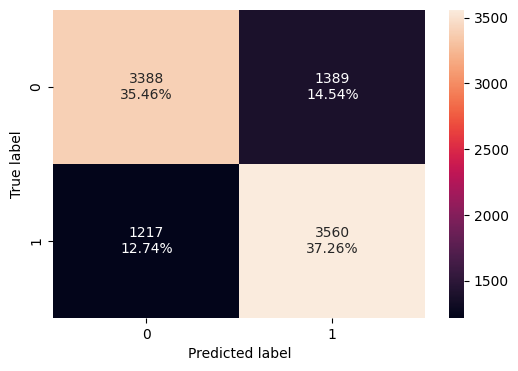

In [121]:
#Calculating the confusion matrix
make_confusion_matrix(y_train_smote, y_train_pred)

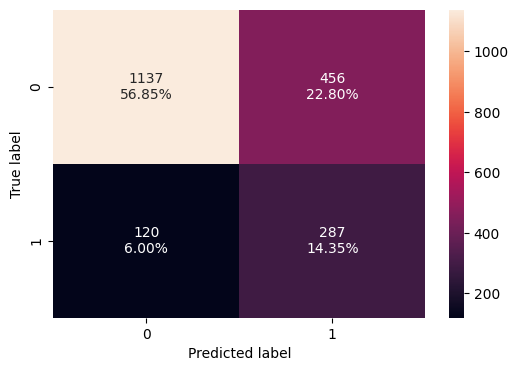

In [122]:
#Calculating the confusion matrix

make_confusion_matrix(y_val,y_val_pred)

### Neural Network with Balanced Data (by applying SMOTE) and Adam Optimizer

Let's build a model with the balanced dataset

In [123]:
backend.clear_session()
#Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [124]:
#Initializing the model
model_4 = Sequential()
model_4.add(Dense(64,activation='relu',input_dim = X_train_smote.shape[1]))
model_4.add(Dense(32,activation='relu'))
model_4.add(Dense(8,activation='relu'))
model_4.add(Dense(1, activation = 'sigmoid'))

In [125]:
model_4.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                768       
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 8)                 264       
                                                                 
 dense_3 (Dense)             (None, 1)                 9         
                                                                 
Total params: 3121 (12.19 KB)
Trainable params: 3121 (12.19 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [126]:
optimizer = tf.keras.optimizers.Adam()

# uncomment one of the following lines to define the metric to be used
# metric = 'accuracy'
metric = keras.metrics.Recall()
# metric = keras.metrics.Precision()
# metric = keras.metrics.F1Score()

In [127]:
model_4.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [128]:
model_4.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                768       
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 8)                 264       
                                                                 
 dense_3 (Dense)             (None, 1)                 9         
                                                                 
Total params: 3121 (12.19 KB)
Trainable params: 3121 (12.19 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [129]:
#Fitting the ANN

history_4 = model_4.fit(
    X_train_smote,y_train_smote,
    batch_size=32,
    epochs=50,
    verbose=1,
    validation_data = (X_val,y_val)
)

Epoch 1/50
299/299 [==============================] - 1s 2ms/step - loss: 0.5732 - recall: 0.7289 - val_loss: 0.6142 - val_recall: 0.7518
Epoch 2/50
299/299 [==============================] - 1s 2ms/step - loss: 0.5116 - recall: 0.7526 - val_loss: 0.5851 - val_recall: 0.7297
Epoch 3/50
299/299 [==============================] - 1s 2ms/step - loss: 0.4815 - recall: 0.7616 - val_loss: 0.4904 - val_recall: 0.6978
Epoch 4/50
299/299 [==============================] - 0s 2ms/step - loss: 0.4598 - recall: 0.7792 - val_loss: 0.4473 - val_recall: 0.6658
Epoch 5/50
299/299 [==============================] - 0s 2ms/step - loss: 0.4448 - recall: 0.7871 - val_loss: 0.4761 - val_recall: 0.7101
Epoch 6/50
299/299 [==============================] - 0s 2ms/step - loss: 0.4326 - recall: 0.7882 - val_loss: 0.4701 - val_recall: 0.7322
Epoch 7/50
299/299 [==============================] - 0s 2ms/step - loss: 0.4207 - recall: 0.7932 - val_loss: 0.5044 - val_recall: 0.7715
Epoch 8/50
299/299 [==============

**Loss function**

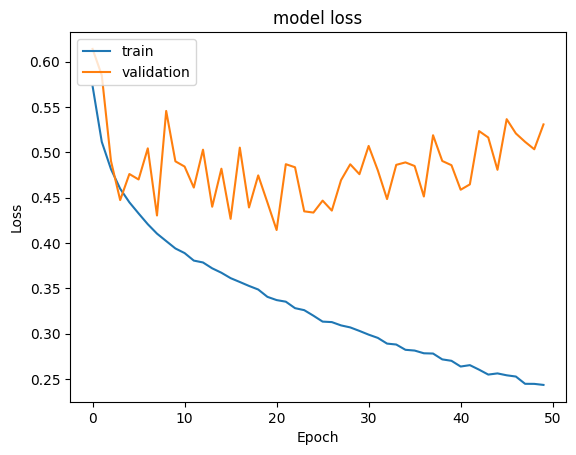

In [130]:
#Plotting Train Loss vs Validation Loss
plt.plot(history_4.history['loss'])
plt.plot(history_4.history['val_loss'])
plt.title('model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

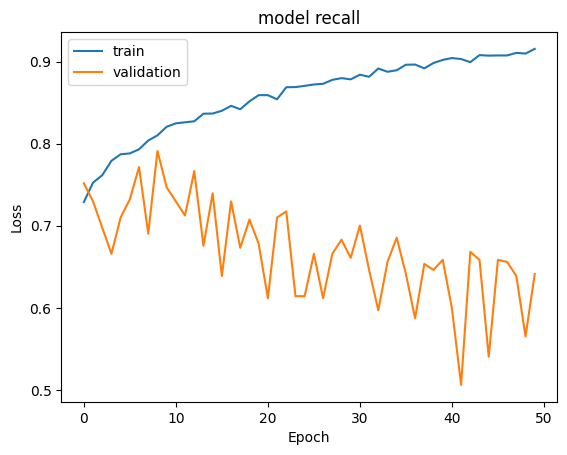

In [131]:
#Plotting Train recall vs Validation recall
plt.plot(history_4.history['recall'])
plt.plot(history_4.history['val_recall'])
plt.title('model recall')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [132]:
y_train_pred = model_4.predict(X_train_smote)
#Predicting the results using 0.5 as the threshold
y_train_pred = (y_train_pred > 0.5)
y_train_pred

299/299 [==============================] - 0s 923us/step


array([[ True],
       [False],
       [False],
       ...,
       [ True],
       [ True],
       [ True]])

In [133]:
y_val_pred = model_4.predict(X_val)
#Predicting the results using 0.5 as the threshold
y_val_pred = (y_val_pred > 0.5)
y_val_pred

63/63 [==============================] - 0s 866us/step


array([[False],
       [False],
       [ True],
       ...,
       [False],
       [False],
       [ True]])

In [134]:
model_name = "NN with SMOTE & Adam"

train_metric_df.loc[model_name] = recall_score(y_train_smote,y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val,y_val_pred)

**Classification report**

In [135]:
cr=classification_report(y_train_smote,y_train_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.93      0.90      0.91      4777
         1.0       0.90      0.93      0.91      4777

    accuracy                           0.91      9554
   macro avg       0.91      0.91      0.91      9554
weighted avg       0.91      0.91      0.91      9554



In [136]:
cr=classification_report(y_val,y_val_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.90      0.84      0.87      1593
         1.0       0.50      0.64      0.56       407

    accuracy                           0.80      2000
   macro avg       0.70      0.74      0.71      2000
weighted avg       0.82      0.80      0.80      2000



**Confusion matrix**

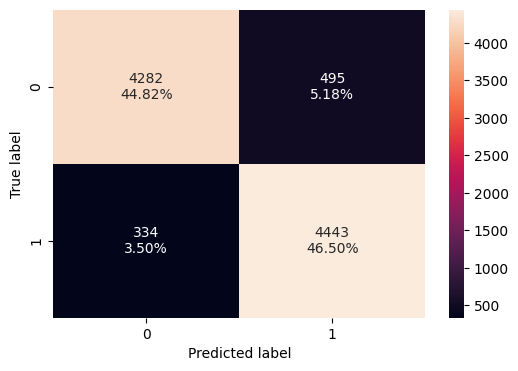

In [137]:
#Calculating the confusion matrix
make_confusion_matrix(y_train_smote, y_train_pred)

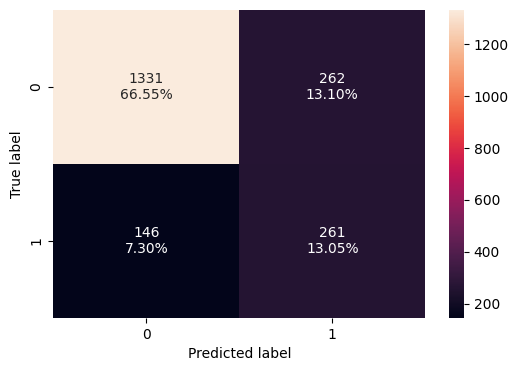

In [138]:
#Calculating the confusion matrix
make_confusion_matrix(y_val,y_val_pred)

### Neural Network with Balanced Data (by applying SMOTE), Adam Optimizer, and Dropout

In [139]:
backend.clear_session()
#Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [140]:
#Initializing the model
model_5 = Sequential()
model_5.add(Dense(64,activation='relu',input_dim = X_train_smote.shape[1]))
model_5.add(Dropout(0.2))
model_5.add(Dense(32,activation='relu'))
model_5.add(Dropout(0.1))
# Adding hidden layer with 8 neurons with relu as activation function
model_5.add(Dense(8,activation='relu'))
model_5.add(Dense(1, activation = 'sigmoid'))

In [141]:
optimizer = tf.keras.optimizers.Adam()

# uncomment one of the following lines to define the metric to be used
# metric = 'accuracy'
metric = keras.metrics.Recall()
# metric = keras.metrics.Precision()
# metric = keras.metrics.F1Score()

In [142]:
model_5.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [143]:
model_5.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                768       
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dropout_1 (Dropout)         (None, 32)                0         
                                                                 
 dense_2 (Dense)             (None, 8)                 264       
                                                                 
 dense_3 (Dense)             (None, 1)                 9         
                                                                 
Total params: 3121 (12.19 KB)
Trainable params: 3121 (12

In [144]:
history_5 = model_5.fit(
    X_train_smote,y_train_smote,
    batch_size=32,
    epochs=100,
    verbose=1,
    validation_data = (X_val,y_val))

Epoch 1/100
299/299 [==============================] - 1s 2ms/step - loss: 0.5986 - recall: 0.6849 - val_loss: 0.6211 - val_recall: 0.7568
Epoch 2/100
299/299 [==============================] - 1s 2ms/step - loss: 0.5515 - recall: 0.7373 - val_loss: 0.5792 - val_recall: 0.7101
Epoch 3/100
299/299 [==============================] - 0s 2ms/step - loss: 0.5323 - recall: 0.7411 - val_loss: 0.5166 - val_recall: 0.6855
Epoch 4/100
299/299 [==============================] - 0s 2ms/step - loss: 0.5108 - recall: 0.7538 - val_loss: 0.4894 - val_recall: 0.6658
Epoch 5/100
299/299 [==============================] - 0s 2ms/step - loss: 0.4951 - recall: 0.7582 - val_loss: 0.5032 - val_recall: 0.7052
Epoch 6/100
299/299 [==============================] - 0s 2ms/step - loss: 0.4835 - recall: 0.7668 - val_loss: 0.4601 - val_recall: 0.7027
Epoch 7/100
299/299 [==============================] - 0s 2ms/step - loss: 0.4716 - recall: 0.7750 - val_loss: 0.4556 - val_recall: 0.6978
Epoch 8/100
299/299 [======

**Loss function**

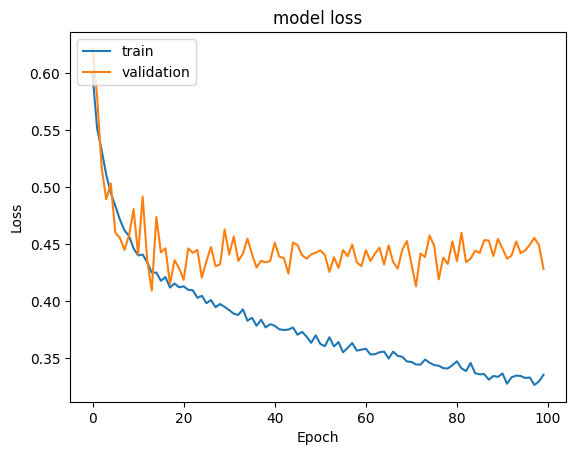

In [145]:
#Plotting Train Loss vs Validation Loss
plt.plot(history_5.history['loss'])
plt.plot(history_5.history['val_loss'])
plt.title('model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

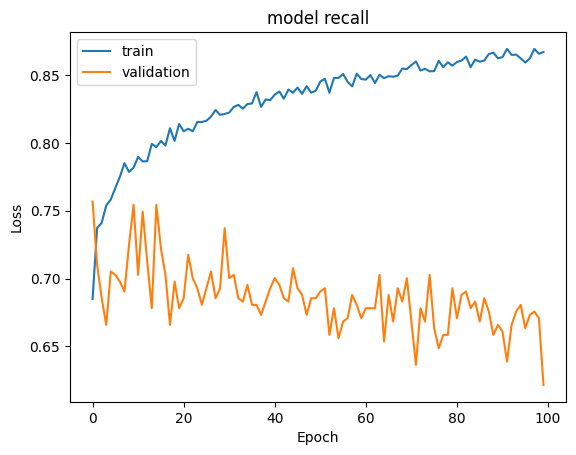

In [146]:
#Plotting Train recall vs Validation recall
plt.plot(history_5.history['recall'])
plt.plot(history_5.history['val_recall'])
plt.title('model recall')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [147]:
y_train_pred = model_5.predict(X_train_smote)
#Predicting the results using 0.5 as the threshold
y_train_pred = (y_train_pred > 0.5)
y_train_pred

299/299 [==============================] - 0s 955us/step


array([[ True],
       [ True],
       [ True],
       ...,
       [ True],
       [False],
       [ True]])

In [148]:
y_val_pred = model_5.predict(X_val)
#Predicting the results using 0.5 as the threshold
y_val_pred = (y_val_pred > 0.5)
y_val_pred

63/63 [==============================] - 0s 943us/step


array([[False],
       [False],
       [False],
       ...,
       [False],
       [False],
       [False]])

In [149]:
model_name = "NN with SMOTE,Adam & Dropout"

train_metric_df.loc[model_name] = recall_score(y_train_smote,y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val,y_val_pred)

**Classification report**

In [150]:
cr=classification_report(y_train_smote,y_train_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.89      0.90      0.89      4777
         1.0       0.89      0.88      0.89      4777

    accuracy                           0.89      9554
   macro avg       0.89      0.89      0.89      9554
weighted avg       0.89      0.89      0.89      9554



In [151]:
#classification report
cr=classification_report(y_val,y_val_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.90      0.86      0.88      1593
         1.0       0.54      0.62      0.58       407

    accuracy                           0.81      2000
   macro avg       0.72      0.74      0.73      2000
weighted avg       0.83      0.81      0.82      2000



**Confusion matrix**

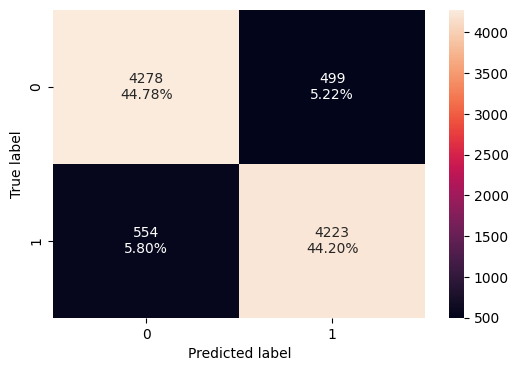

In [152]:
#Calculating the confusion matrix
make_confusion_matrix(y_train_smote, y_train_pred)

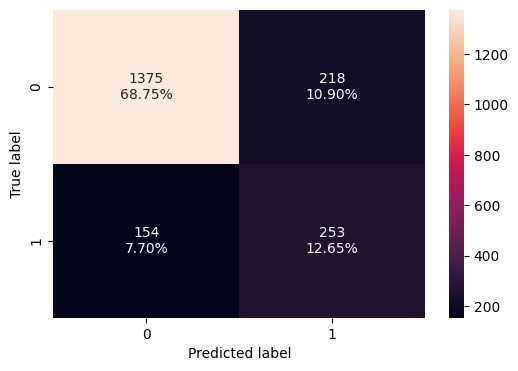

In [153]:
#Calculating the confusion matrix
make_confusion_matrix(y_val,y_val_pred)

## Model Performance Comparison and Final Model Selection

In [154]:
print("Training performance comparison")
train_metric_df

Training performance comparison


,recall
NN with SGD,0.049060
NN with Adam,0.513491
NN with Adam & Dropout,0.535568
NN with SMOTE & SGD,0.745238
NN with SMOTE & Adam,0.930082
"NN with SMOTE,Adam & Dropout",0.884028


In [155]:
print("Validation set performance comparison")
valid_metric_df

Validation set performance comparison


,recall
NN with SGD,0.044226
NN with Adam,0.410319
NN with Adam & Dropout,0.461916
NN with SMOTE & SGD,0.705160
NN with SMOTE & Adam,0.641278
"NN with SMOTE,Adam & Dropout",0.621622


In [156]:
train_metric_df - valid_metric_df

,recall
NN with SGD,0.004834
NN with Adam,0.103172
NN with Adam & Dropout,0.073652
NN with SMOTE & SGD,0.040078
NN with SMOTE & Adam,0.288804
"NN with SMOTE,Adam & Dropout",0.262406


In [157]:
y_test_pred = model_5.predict(X_test)
y_test_pred = (y_test_pred > 0.5)
print(y_test_pred)

63/63 [==============================] - 0s 974us/step
[[False]
 [False]
 [False]
 ...
 [ True]
 [False]
 [False]]


In [158]:
#lets print classification report
cr=classification_report(y_test,y_test_pred)
print(cr)

              precision    recall  f1-score   support

         0.0       0.91      0.86      0.88      1593
         1.0       0.55      0.65      0.59       407

    accuracy                           0.82      2000
   macro avg       0.73      0.76      0.74      2000
weighted avg       0.83      0.82      0.82      2000



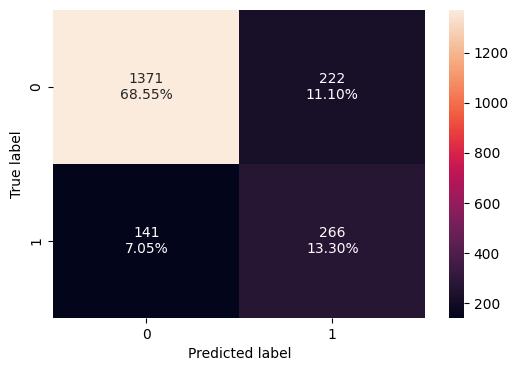

In [159]:
#Calculating the confusion matrix
make_confusion_matrix(y_test,y_test_pred)

## Actionable Insights and Business Recommendations

<font size=6 color='blue'>Power Ahead</font>
___